In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [4]:
df=pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")

In [5]:
df.head()

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany


In [6]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Product_Name       15000 non-null  str    
 1   Brand              15000 non-null  str    
 2   Category           15000 non-null  str    
 3   Usage_Frequency    15000 non-null  str    
 4   Price_USD          15000 non-null  float64
 5   Rating             15000 non-null  float64
 6   Number_of_Reviews  15000 non-null  int64  
 7   Product_Size       15000 non-null  str    
 8   Skin_Type          15000 non-null  str    
 9   Gender_Target      15000 non-null  str    
 10  Packaging_Type     15000 non-null  str    
 11  Main_Ingredient    15000 non-null  str    
 12  Cruelty_Free       15000 non-null  bool   
 13  Country_of_Origin  15000 non-null  str    
dtypes: bool(1), float64(2), int64(1), str(10)
memory usage: 1.5 MB


In [7]:
df.describe()

,Price_USD,Rating,Number_of_Reviews
count,15000.000000,15000.000000,15000.000000
mean,80.134108,3.002327,5014.231333
std,40.402983,1.168029,2855.665464
min,10.000000,1.000000,52.000000
25%,45.480000,2.000000,2562.000000
50%,80.040000,3.000000,5002.000000
75%,114.760000,4.000000,7497.000000
max,149.990000,5.000000,10000.000000


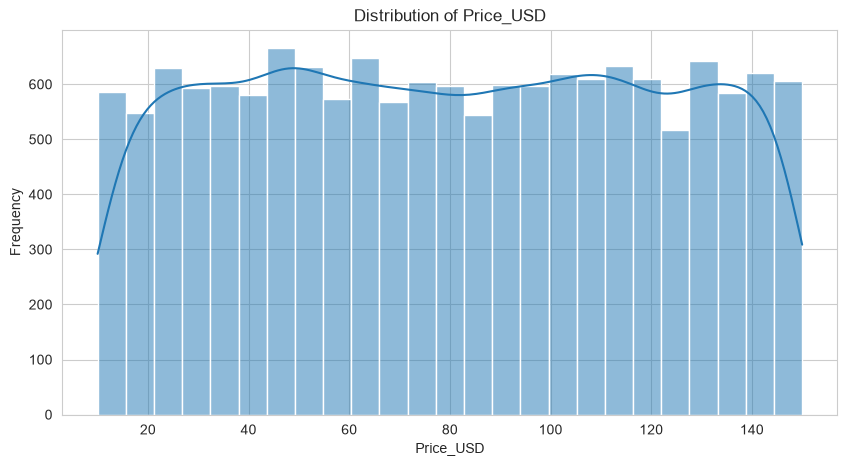

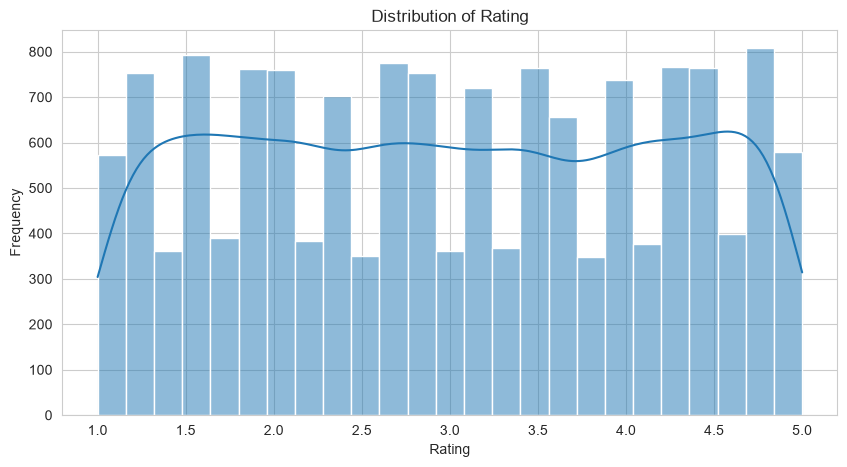

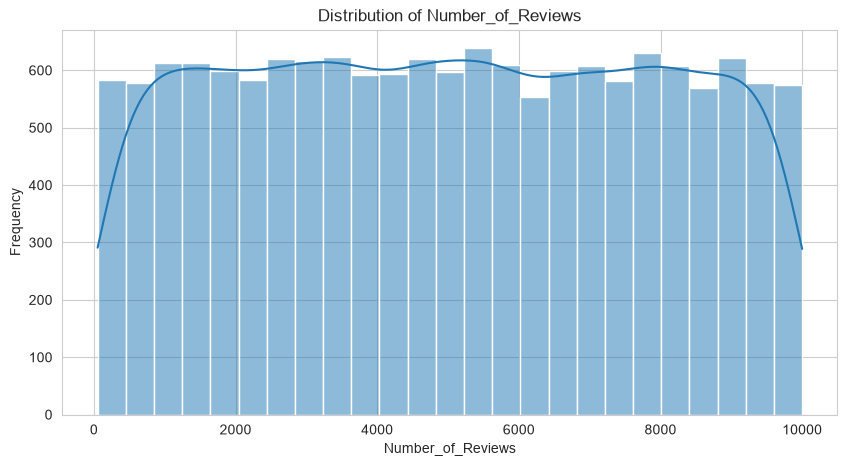

In [8]:
numerical_columns=["Price_USD","Rating","Number_of_Reviews"]
for col in numerical_columns:
  plt.figure(figsize=(10,5))
  sns.histplot(df[col],kde=True)
  plt.title(f"Distribution of {col}")
  plt.xlabel(col)
  plt.ylabel("Frequency")
  plt.show()

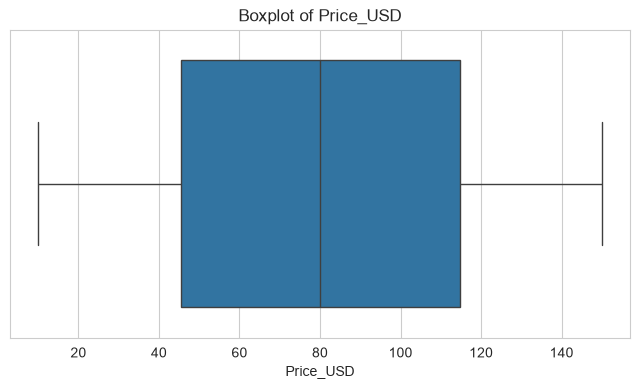

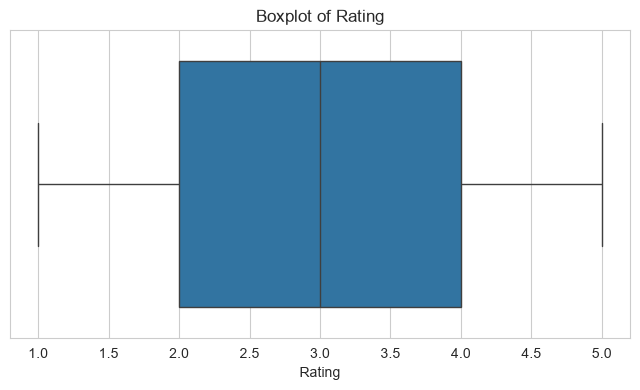

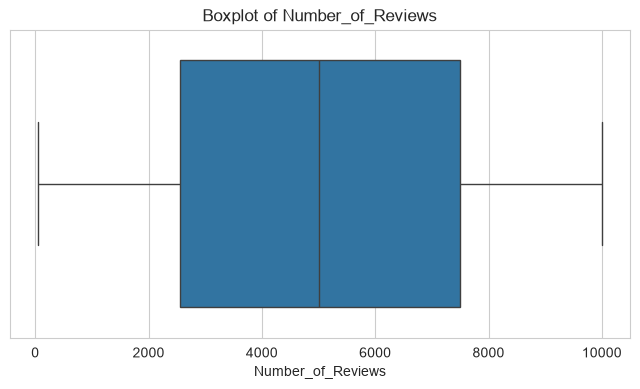

In [9]:
for col in numerical_columns:
  plt.figure(figsize=(8,4))
  sns.boxplot(x=df[col])
  plt.title(f"Boxplot of {col}")
  plt.show()

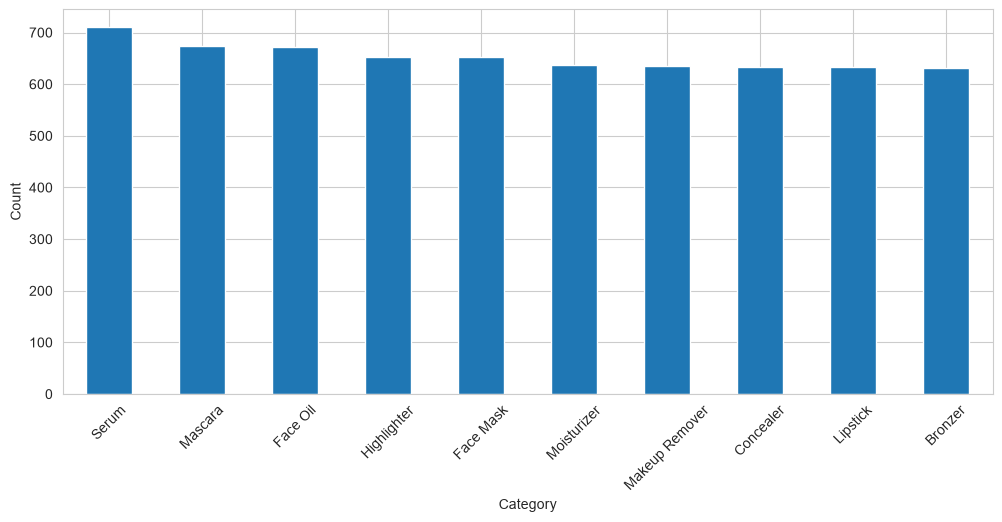

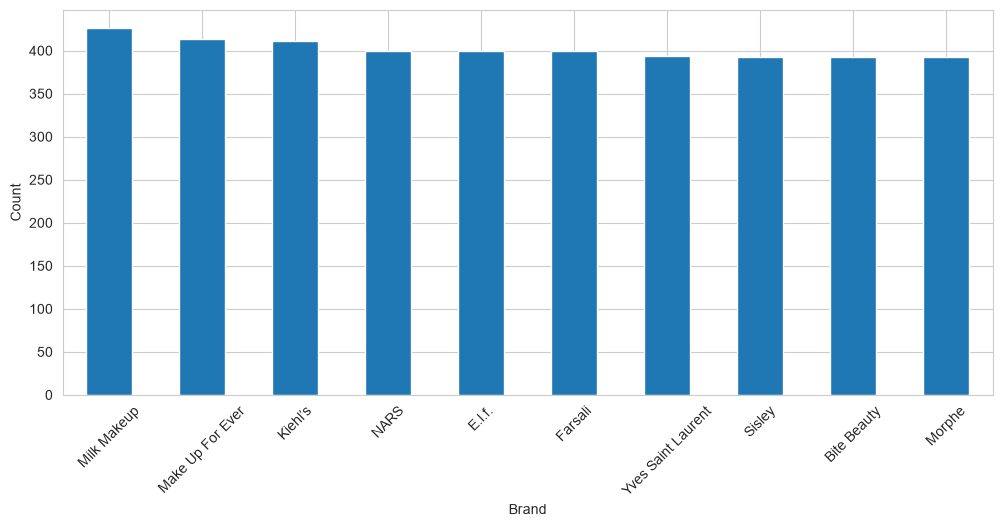

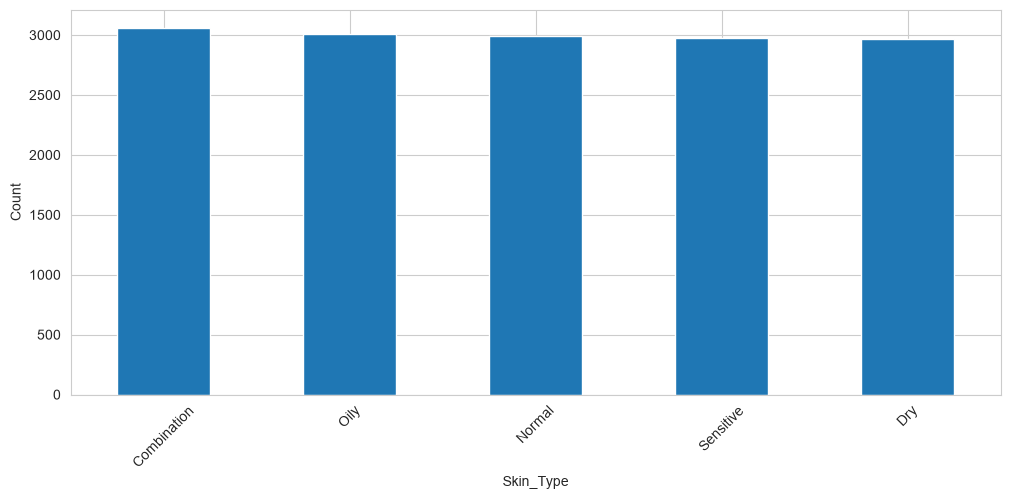

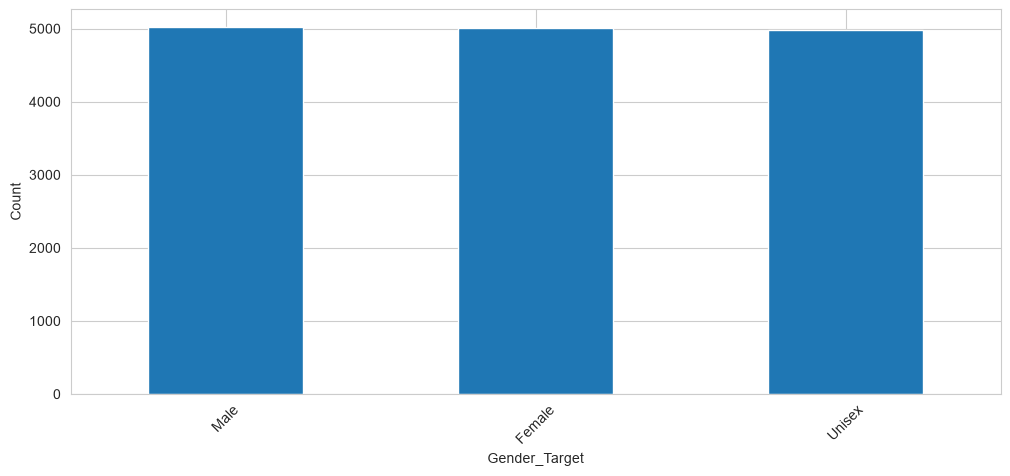

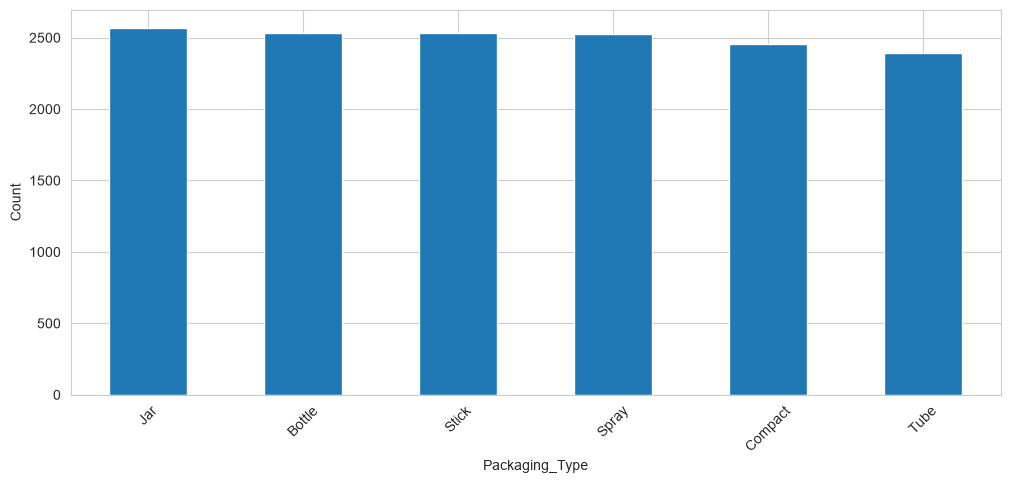

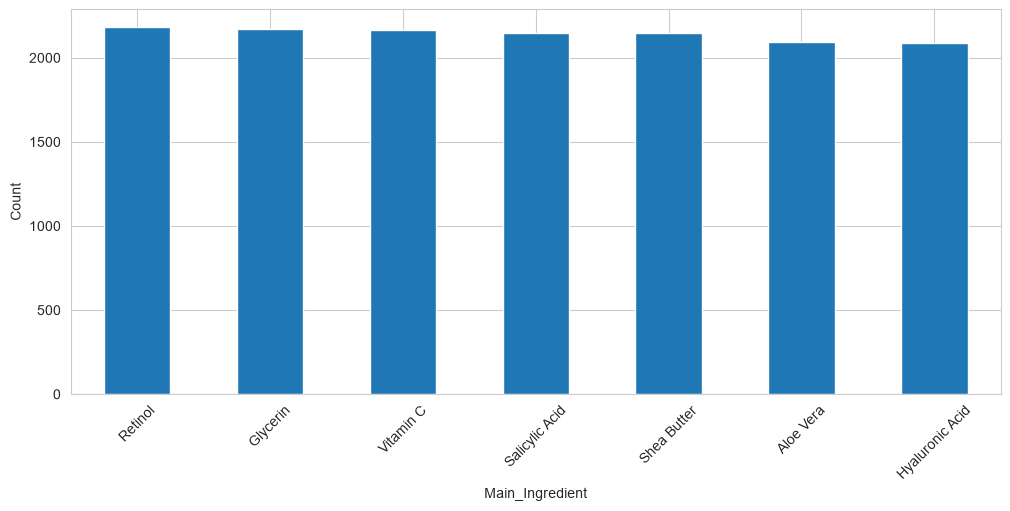

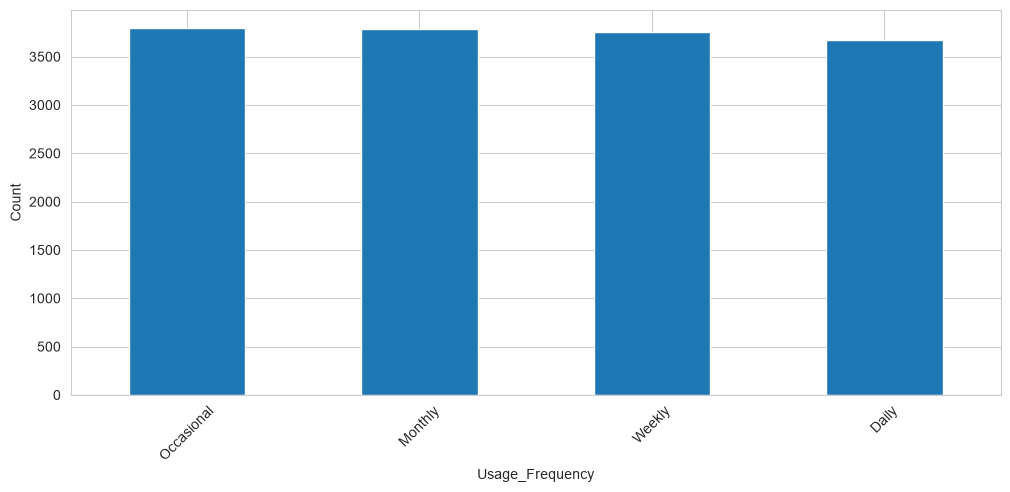

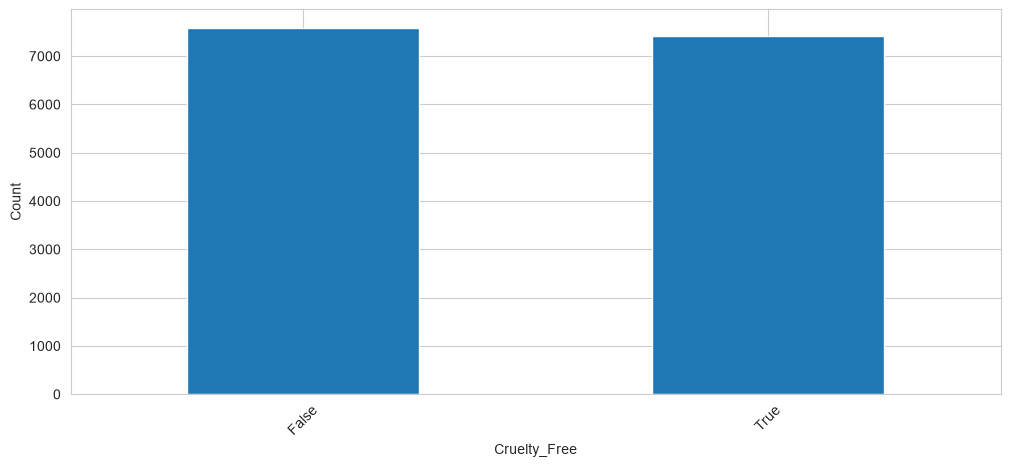

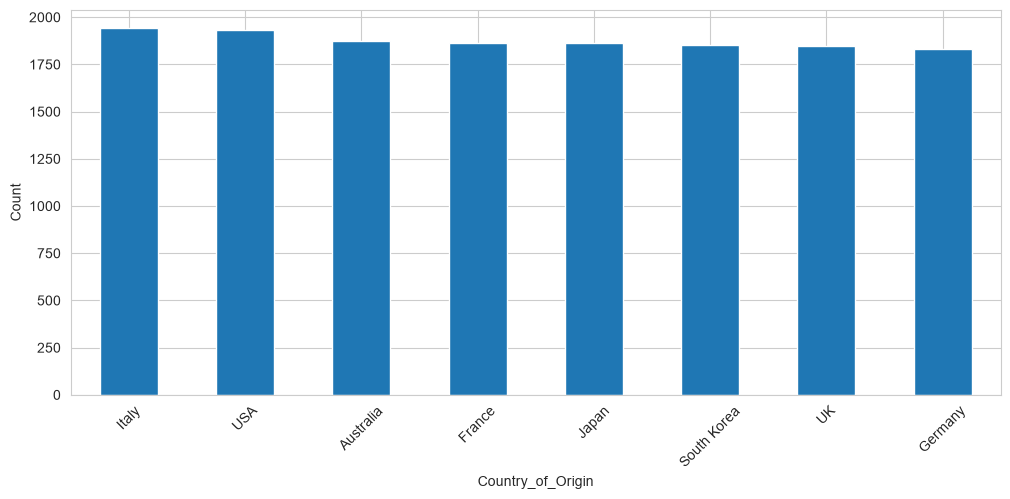

In [10]:
categorical_columns=["Category","Brand","Skin_Type","Gender_Target","Packaging_Type","Main_Ingredient","Usage_Frequency","Cruelty_Free","Country_of_Origin"]
for col in categorical_columns:
  plt.figure(figsize=(12,5))
  df[col].value_counts().head(10).plot(kind='bar')
  plt.xlabel(col)
  plt.ylabel("Count")
  plt.xticks(rotation=45)
  plt.show()

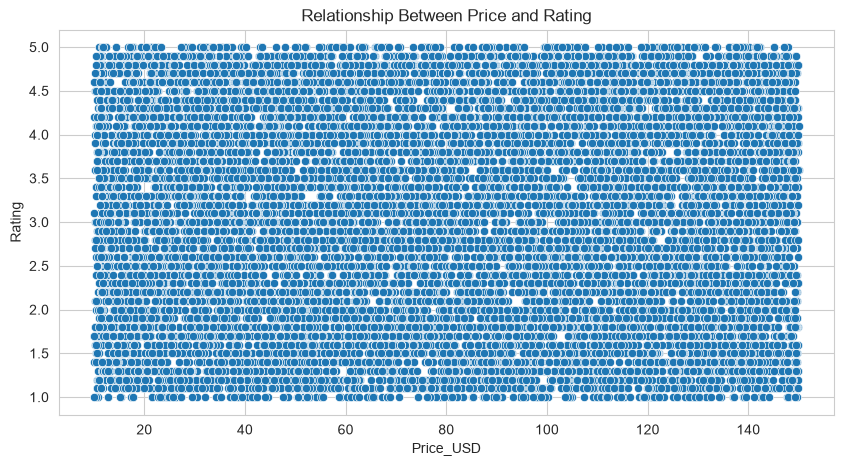

In [11]:
sns.scatterplot(data=df,x="Price_USD",y="Rating")
plt.title("Relationship Between Price and Rating")
plt.show()

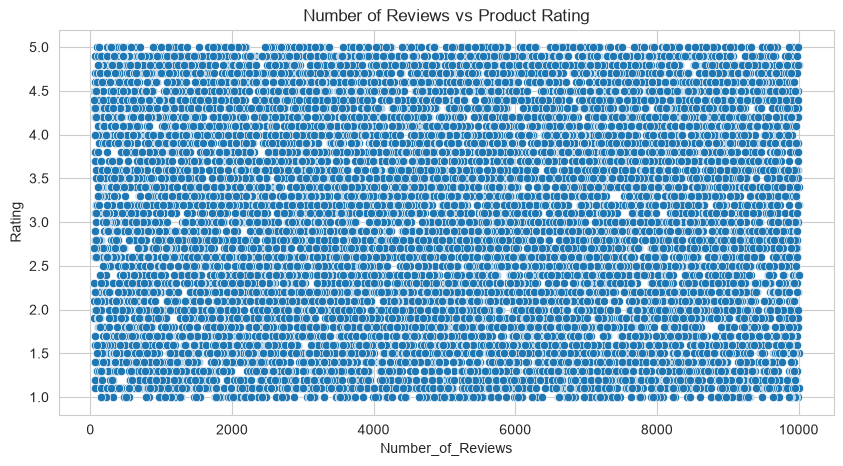

In [12]:
sns.scatterplot(data=df,x="Number_of_Reviews",y="Rating")
plt.title("Number of Reviews vs Product Rating")
plt.show()

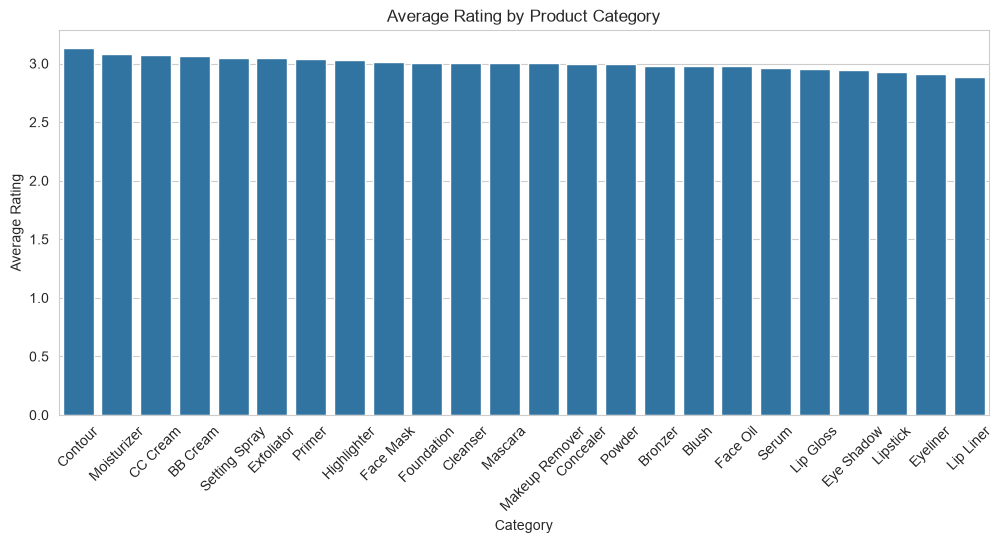

In [13]:
category_rating = df.groupby("Category")["Rating"].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 5))
sns.barplot(x=category_rating.index,y=category_rating.values)
plt.title("Average Rating by Product Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.show()

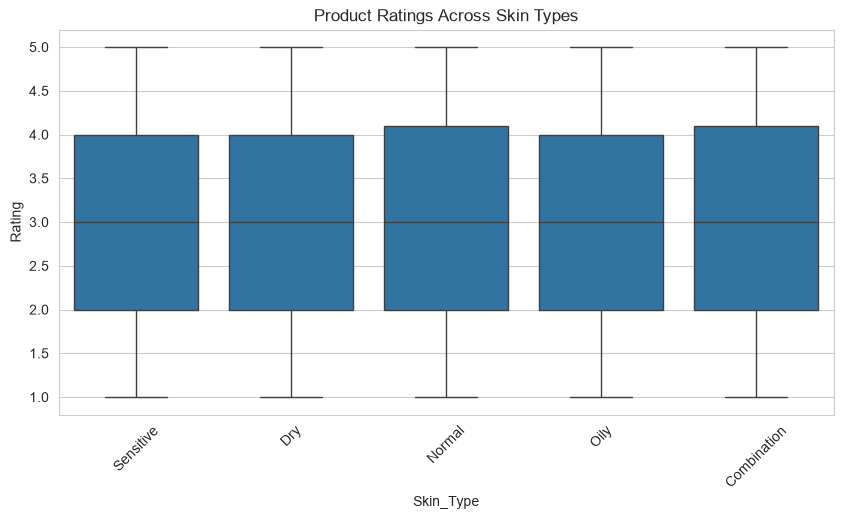

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df,x="Skin_Type",y="Rating")
plt.title("Product Ratings Across Skin Types")
plt.xticks(rotation=45)
plt.show()

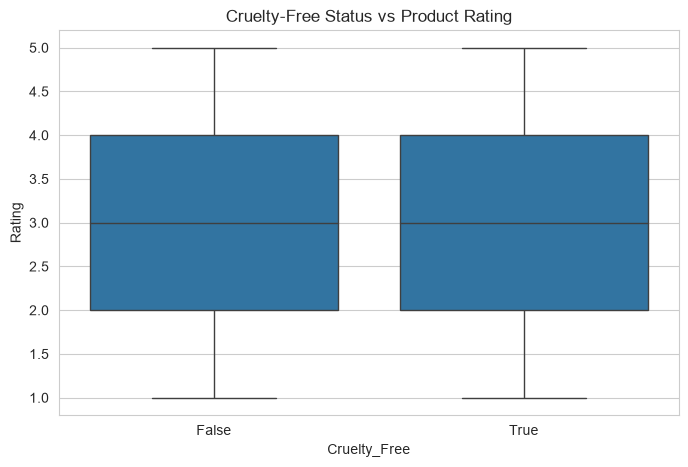

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df,x="Cruelty_Free",y="Rating")
plt.title("Cruelty-Free Status vs Product Rating")
plt.show()

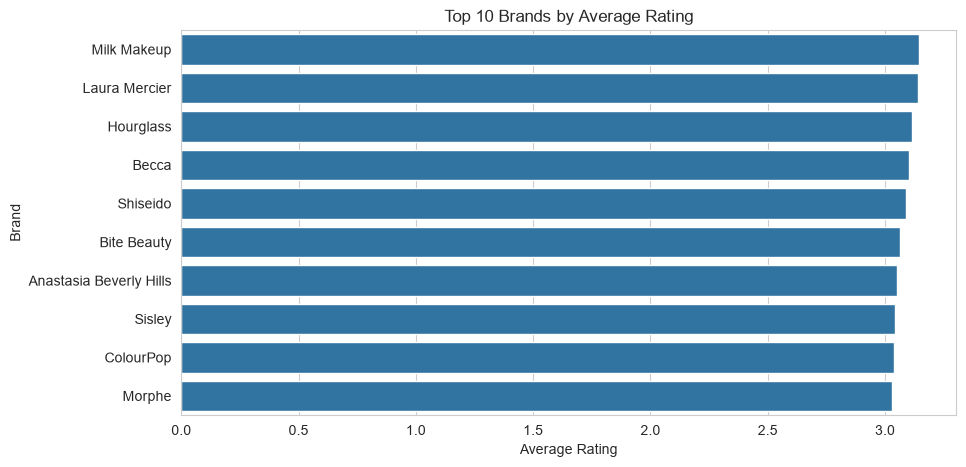

In [16]:
brand_rating = (df.groupby("Brand")["Rating"].mean().sort_values(ascending=False).head(10))
sns.barplot(x=brand_rating.values,y=brand_rating.index)
plt.title("Top 10 Brands by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Brand")
plt.show()

In [17]:
pearson_corr = df["Price_USD"].corr(df["Rating"],method="pearson")
spearman_corr = df["Price_USD"].corr(df["Rating"],method="spearman")
print("Pearson Correlation:", pearson_corr)
print("Spearman Correlation:", spearman_corr)

Pearson Correlation: -0.005232067349474286
Spearman Correlation: -0.00542772781855614


In [18]:
def correlation_strength(value):
    if abs(value) < 0.3:
        return "Weak Relationship"
    elif abs(value) < 0.7:
        return "Moderate Relationship"
    else:
        return "Strong Relationship"
print("Pearson:", correlation_strength(pearson_corr))
print("Spearman:", correlation_strength(spearman_corr))

Pearson: Weak Relationship
Spearman: Weak Relationship


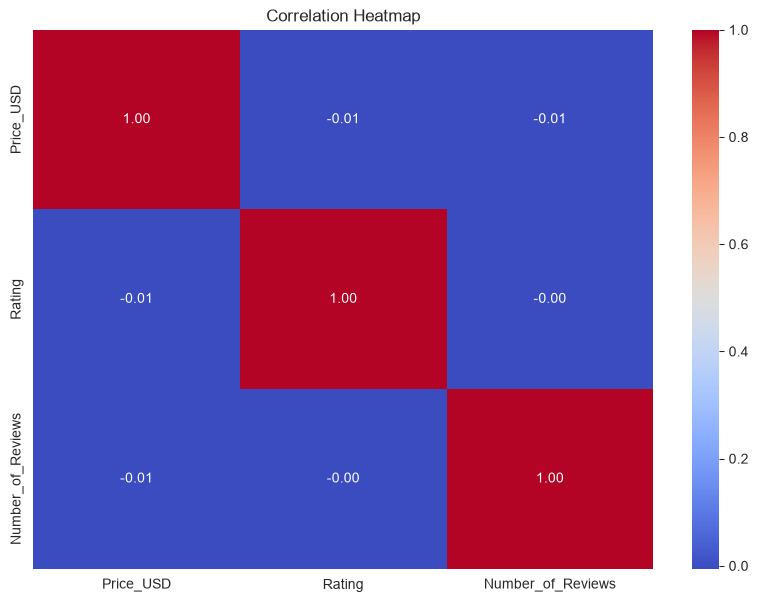

In [19]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

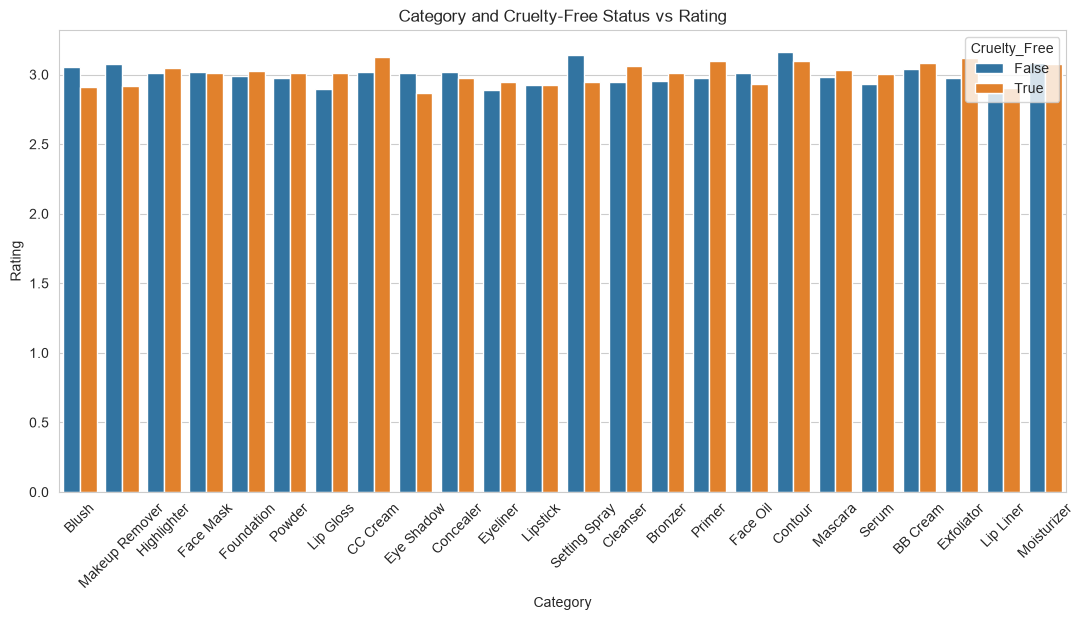

In [20]:
plt.figure(figsize=(13, 6))
sns.barplot(data=df,x="Category",y="Rating",hue="Cruelty_Free",errorbar=None)
plt.title("Category and Cruelty-Free Status vs Rating")
plt.xticks(rotation=45)
plt.show()

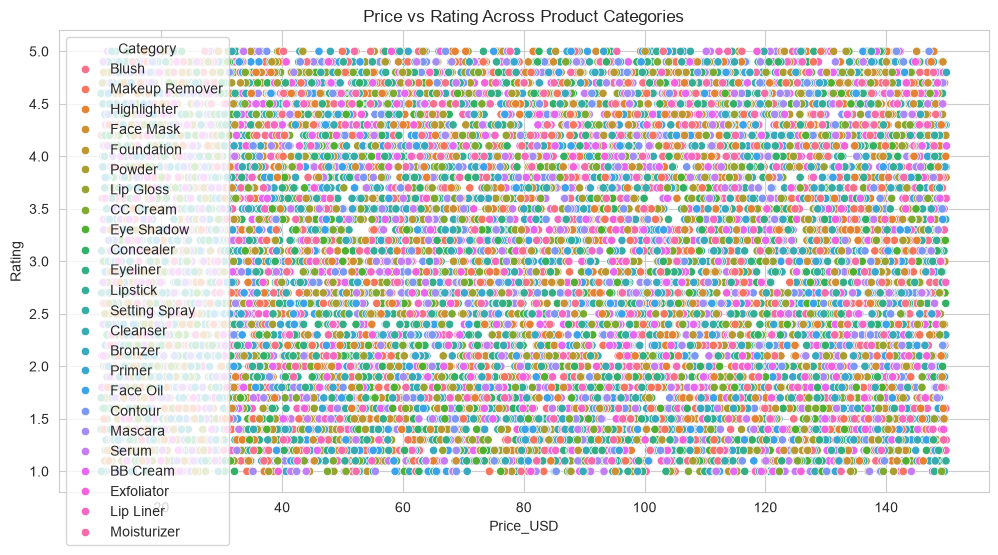

In [21]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df,x="Price_USD",y="Rating",hue="Category")
plt.title("Price vs Rating Across Product Categories")
plt.show()

In [22]:
pearson_result = stats.pearsonr(df["Price_USD"],df["Rating"])
print("Correlation:", pearson_result.statistic)
print("P-value:", pearson_result.pvalue)

Correlation: -0.005232067349474294
P-value: 0.5216878855373297


In [24]:
spearman_result = stats.spearmanr(df["Price_USD"],df["Rating"])
print("Correlation:", spearman_result.statistic)
print("P-value:", spearman_result.pvalue)

Correlation: -0.00542772781855614
P-value: 0.506237482009281


In [25]:
group1 = df[df["Cruelty_Free"].astype(str).str.lower() == "yes"]["Rating"]
group2 = df[df["Cruelty_Free"].astype(str).str.lower() == "no"]["Rating"]
t_stat, p_value = stats.ttest_ind(group1,group2,equal_var=False)
print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: nan
P-value: nan


C:\Users\shaik\AppData\Local\Temp\ipykernel_21608\3445784719.py:3: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat, p_value = stats.ttest_ind(group1,group2,equal_var=False)


In [26]:
groups = [group["Rating"].values
          for _, group in df.groupby("Category")
]
f_stat, p_value = stats.f_oneway(*groups)
print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 1.4306458148288344
P-value: 0.08297068948012944


In [27]:
if p_value<0.05:
  print("Statistically significance difference")
else:
  print("No statistically significance difference")

No statistically significance difference


In [28]:
df_fe = df.copy()
print("Original Shape:", df_fe.shape)

Original Shape: (15000, 14)


In [29]:
df_fe["Price_Category"] = pd.qcut(df_fe["Price_USD"].rank(method="first"),q=3,labels=["Budget", "Mid-Range", "Premium"])
display(df_fe[["Price_USD", "Price_Category"]].head(10))

,Price_USD,Price_Category
0,67.85,Mid-Range
1,116.43,Premium
2,90.84,Mid-Range
3,55.17,Budget
4,140.56,Premium
5,135.82,Premium
6,148.99,Premium
7,21.43,Budget
8,113.09,Premium
9,133.57,Premium


In [30]:
df_fe["Product_Popularity"] = pd.qcut(df_fe["Number_of_Reviews"].rank(method="first"),q=3,labels=["Low", "Medium", "High"])
display(df_fe[["Number_of_Reviews", "Product_Popularity"]].head(10))

,Number_of_Reviews,Product_Popularity
0,686,Low
1,5483,Medium
2,5039,Medium
3,6202,Medium
4,297,Low
5,9405,High
6,2423,Low
7,8032,High
8,2468,Low
9,4127,Medium


In [31]:
df_fe["Log_Reviews"] = np.log1p(df_fe["Number_of_Reviews"])
display(df_fe[["Number_of_Reviews", "Log_Reviews"]].head())

,Number_of_Reviews,Log_Reviews
0,686,6.532334
1,5483,8.609590
2,5039,8.525161
3,6202,8.732788
4,297,5.697093


In [32]:
brand_counts = df_fe["Brand"].value_counts()
df_fe["Brand_Frequency"] = df_fe["Brand"].map(brand_counts)
display(df_fe[["Brand", "Brand_Frequency"]].head())

,Brand,Brand_Frequency
0,Drunk Elephant,368
1,Laura Mercier,355
2,Natasha Denona,366
3,Ilia Beauty,379
4,Charlotte Tilbury,364


In [33]:
df_fe["Price_Review_Interaction"] = (df_fe["Price_USD"] * df_fe["Log_Reviews"])
display(df_fe[["Price_USD", "Log_Reviews", "Price_Review_Interaction"]].head())

,Price_USD,Log_Reviews,Price_Review_Interaction
0,67.85,6.532334,443.218882
1,116.43,8.609590,1002.414568
2,90.84,8.525161,774.425658
3,55.17,8.732788,481.787932
4,140.56,5.697093,800.783460


In [34]:
categorical_features = [
    "Category",
    "Skin_Type",
    "Gender_Target",
    "Packaging_Type",
    "Cruelty_Free",
    "Usage_Frequency"]
df_encoded = pd.get_dummies(df_fe,columns=categorical_features,drop_first=True,dtype=int)
display(df_encoded.head())
print("Shape after encoding:", df_encoded.shape)

,Product_Name,Brand,Price_USD,Rating,Number_of_Reviews,Product_Size,Main_Ingredient,Country_of_Origin,Price_Category,Product_Popularity,...,Gender_Target_Unisex,Packaging_Type_Compact,Packaging_Type_Jar,Packaging_Type_Spray,Packaging_Type_Stick,Packaging_Type_Tube,Cruelty_Free_True,Usage_Frequency_Monthly,Usage_Frequency_Occasional,Usage_Frequency_Weekly
0,Ultra Face Mask,Drunk Elephant,67.85,1.4,686,30ml,Retinol,Australia,Mid-Range,Low,...,0,0,0,0,0,1,0,0,0,1
1,Ultra Lipstick,Laura Mercier,116.43,4.2,5483,250ml,Shea Butter,UK,Premium,Medium,...,1,0,0,0,0,0,0,0,1,0
2,Ultra Serum,Natasha Denona,90.84,1.6,5039,100ml,Aloe Vera,Italy,Mid-Range,Medium,...,0,1,0,0,0,0,1,0,0,0
3,Divine Serum,Ilia Beauty,55.17,3.2,6202,250ml,Glycerin,South Korea,Budget,Medium,...,0,0,0,0,0,1,1,0,1,0
4,Super Foundation,Charlotte Tilbury,140.56,1.7,297,100ml,Glycerin,Germany,Premium,Low,...,0,1,0,0,0,0,0,0,1,0


Shape after encoding: (15000, 51)


In [35]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler()
df_fe["Price_Normalized"] = minmax.fit_transform(df_fe[["Price_USD"]])
display(df_fe[["Price_USD", "Price_Normalized"]].head())

,Price_USD,Price_Normalized
0,67.85,0.413244
1,116.43,0.760269
2,90.84,0.577470
3,55.17,0.322666
4,140.56,0.932638


In [36]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_fe["Price_Standardized"] = scaler.fit_transform(df_fe[["Price_USD"]])
display(df_fe[["Price_USD", "Price_Standardized"]].head())

,Price_USD,Price_Standardized
0,67.85,-0.304050
1,116.43,0.898377
2,90.84,0.264987
3,55.17,-0.617898
4,140.56,1.495630


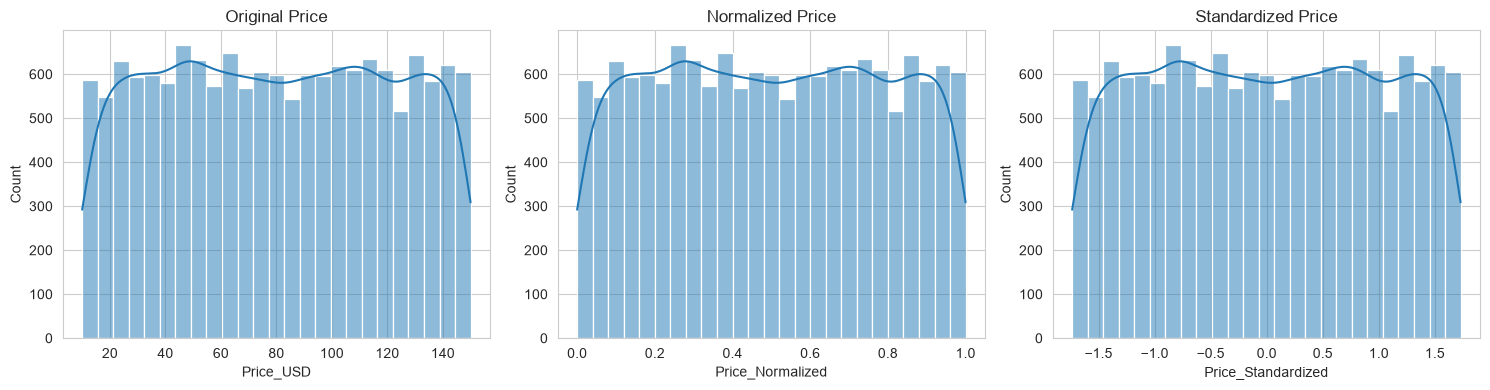

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_fe["Price_USD"], kde=True, ax=axes[0])
axes[0].set_title("Original Price")
sns.histplot(df_fe["Price_Normalized"], kde=True, ax=axes[1])
axes[1].set_title("Normalized Price")
sns.histplot(df_fe["Price_Standardized"], kde=True, ax=axes[2])
axes[2].set_title("Standardized Price")
plt.tight_layout()
plt.show()

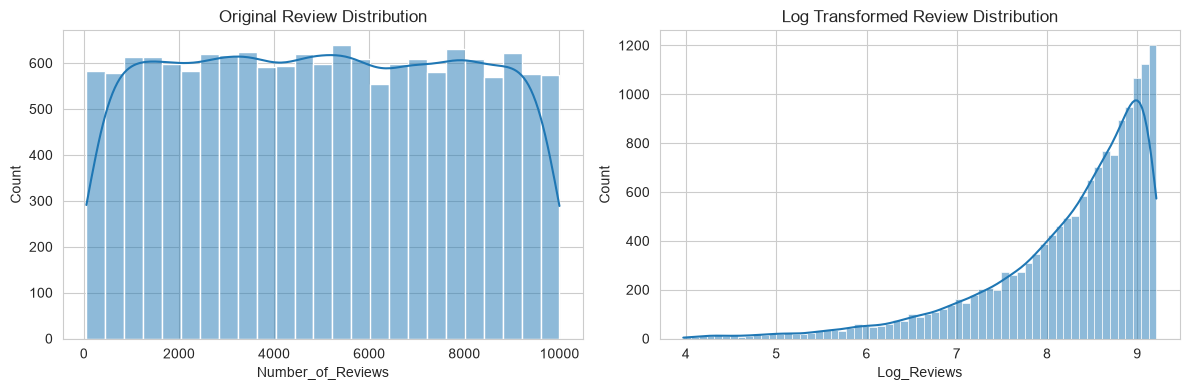

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_fe["Number_of_Reviews"],kde=True,ax=axes[0])
axes[0].set_title("Original Review Distribution")
sns.histplot(df_fe["Log_Reviews"],kde=True,ax=axes[1])
axes[1].set_title("Log Transformed Review Distribution")
plt.tight_layout()
plt.show()

In [39]:
new_features = [
    "Price_Category",
    "Product_Popularity",
    "Log_Reviews",
    "Brand_Frequency",
    "Price_Review_Interaction",
    "Price_Normalized",
    "Price_Standardized"]
display(df_fe[new_features].head(10))
print("Total Original Features:", df.shape[1])
print("Total Engineered Features:", df_fe.shape[1])

,Price_Category,Product_Popularity,Log_Reviews,Brand_Frequency,Price_Review_Interaction,Price_Normalized,Price_Standardized
0,Mid-Range,Low,6.532334,368,443.218882,0.413244,-0.304050
1,Premium,Medium,8.609590,355,1002.414568,0.760269,0.898377
2,Mid-Range,Medium,8.525161,366,774.425658,0.577470,0.264987
3,Budget,Medium,8.732788,379,481.787932,0.322666,-0.617898
4,Premium,Low,5.697093,364,800.783460,0.932638,1.495630
5,Premium,High,9.149103,358,1242.631178,0.898778,1.378308
6,Premium,Low,7.793174,357,1161.105046,0.992857,1.704285
7,Budget,High,8.991313,357,192.683845,0.081649,-1.453013
8,Premium,Low,7.811568,346,883.410280,0.736410,0.815707
9,Premium,Medium,8.325548,366,1112.043487,0.882706,1.322617


Total Original Features: 14
Total Engineered Features: 21
